# MoodSense AI: Facial-Expression Mood Inference
## CNN Model Evaluation and Local Inference Engine

This notebook evaluates the exact compact ONNX CNN used by the local Flask
application. A frontal face is located with an OpenCV Haar cascade, converted
to grayscale, resized to 64 × 64 pixels, normalized to `[-1, 1]`, and assigned
one of seven visible-expression classes: **angry, disgust, fear, happy, sad,
surprise, or neutral**.

> **Interpretation boundary:** A facial expression is an observable movement,
> not a direct measurement of a person's internal mood. The output is not a
> diagnosis and must not be used alone for health, employment, education,
> policing, insurance, or other high-stakes decisions.

### 1. Reproducibility and model provenance

The deployment artifact is an ONNX conversion of the MIT-licensed quantized
TensorFlow Lite model distributed by the open-source `fer` project. The upstream
model was developed for FER-2013 facial-expression recognition. MoodSense adds safe image
validation, frontal-face localization, local inference, browser camera/upload
support, per-user SQLite records, and this reproducible evaluation.

The notebook uses the official **FER-2013 PrivateTest partition** and never
uses those 3,589 observations to update the model weights.

In [1]:
from pathlib import Path
import json, platform, time, warnings
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

from facial_service import FACIAL_LABELS, MODEL_PATH
from facial_evaluation import (
    ensure_fer2013_csv, load_private_test, evaluate_private_test,
    evaluation_artifacts
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 20)

ROOT = Path.cwd()
METADATA_PATH = ROOT / 'models' / 'facial_model_metadata.json'
print('Python:', platform.python_version())
print('OpenCV:', cv2.__version__)
print('scikit-learn:', sklearn.__version__)
print('Model file:', MODEL_PATH)
print('Model size:', f'{MODEL_PATH.stat().st_size / 1024:.1f} KiB')

Python: 3.12.13
OpenCV: 4.13.0
scikit-learn: 1.8.0
Model file: /workspace/scratch/cb04da410e0b/moodsense_local/models/facial_expression_model.onnx
Model size: 90.2 KiB


### 2. Evaluation dataset

FER-2013 contains 48 × 48 grayscale face crops labelled from 0 to 6. The CSV
contains predefined `Training`, `PublicTest`, and `PrivateTest` partitions. Only
the 3,589 `PrivateTest` images are evaluated here. On first rerun, the helper
downloads the approximately 92 MB archive and verifies its SHA-256 checksum.
The dataset is intentionally excluded from the application archive.

In [2]:
csv_path = ensure_fer2013_csv()
data = load_private_test(csv_path)
data['label'] = data['emotion'].map(dict(enumerate(FACIAL_LABELS)))
print(f'PrivateTest shape: {data.shape[0]:,} rows × {data.shape[1]} columns')
print('Missing values:', int(data.isna().sum().sum()))
display(data[['emotion','label','Usage']].head())

PrivateTest shape: 3,589 rows × 4 columns
Missing values: 0
   emotion     label        Usage
0        0     angry  PrivateTest
1        5  surprise  PrivateTest
2        6   neutral  PrivateTest
3        4       sad  PrivateTest
4        2      fear  PrivateTest


      Class  Frequency  Percentage
0     Angry        491       13.68
1   Disgust         55        1.53
2      Fear        528       14.71
3     Happy        879       24.49
4       Sad        594       16.55
5  Surprise        416       11.59
6   Neutral        626       17.44


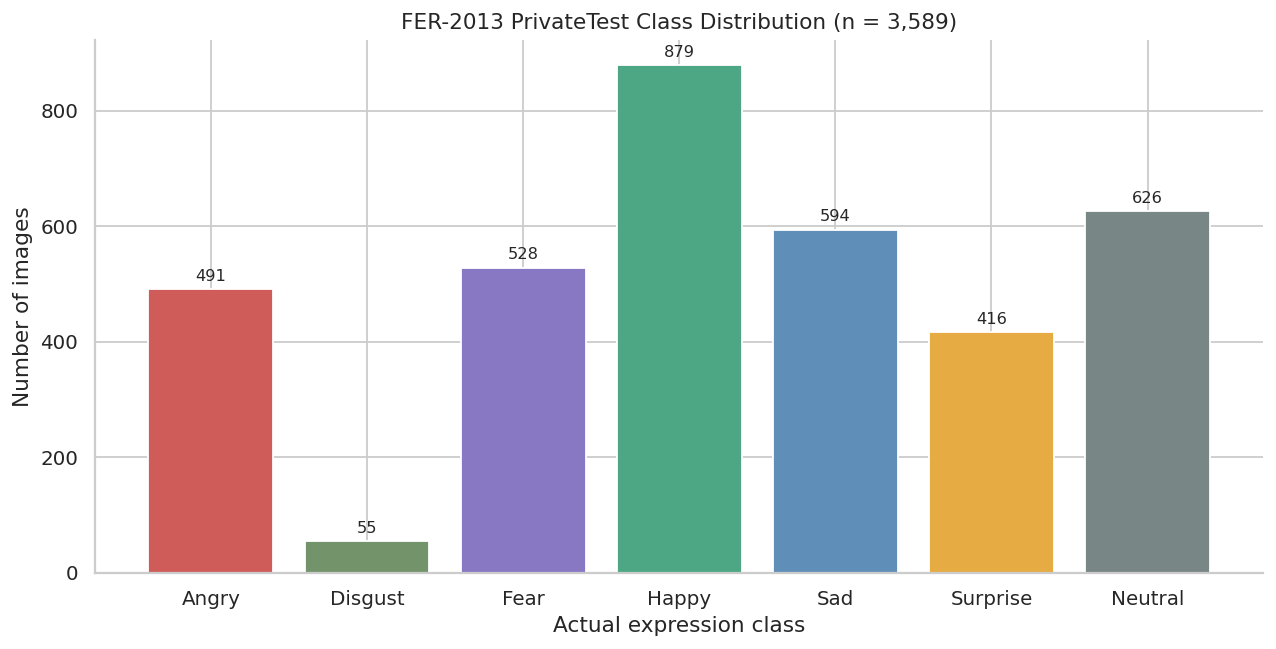

In [3]:
counts = data['label'].value_counts().reindex(FACIAL_LABELS)
distribution = pd.DataFrame({
    'Class': [label.title() for label in counts.index],
    'Frequency': counts.values,
    'Percentage': (counts.values / len(data) * 100).round(2),
})
display(distribution)

palette = ['#CF5C59','#73936A','#8878C4','#4DA784','#5F8FB8','#E7AB43','#788785']
fig, ax = plt.subplots(figsize=(10,5.2))
bars = ax.bar(distribution['Class'], distribution['Frequency'], color=palette)
ax.bar_label(bars, padding=3, fontsize=9)
ax.set(title='FER-2013 PrivateTest Class Distribution (n = 3,589)',
       xlabel='Actual expression class', ylabel='Number of images')
sns.despine()
plt.tight_layout()
plt.show()

**Interpretation.** The test data are naturally imbalanced. Happy has 879
examples, whereas disgust has only 55. For this reason, balanced accuracy and
macro F1 are reported alongside ordinary accuracy.

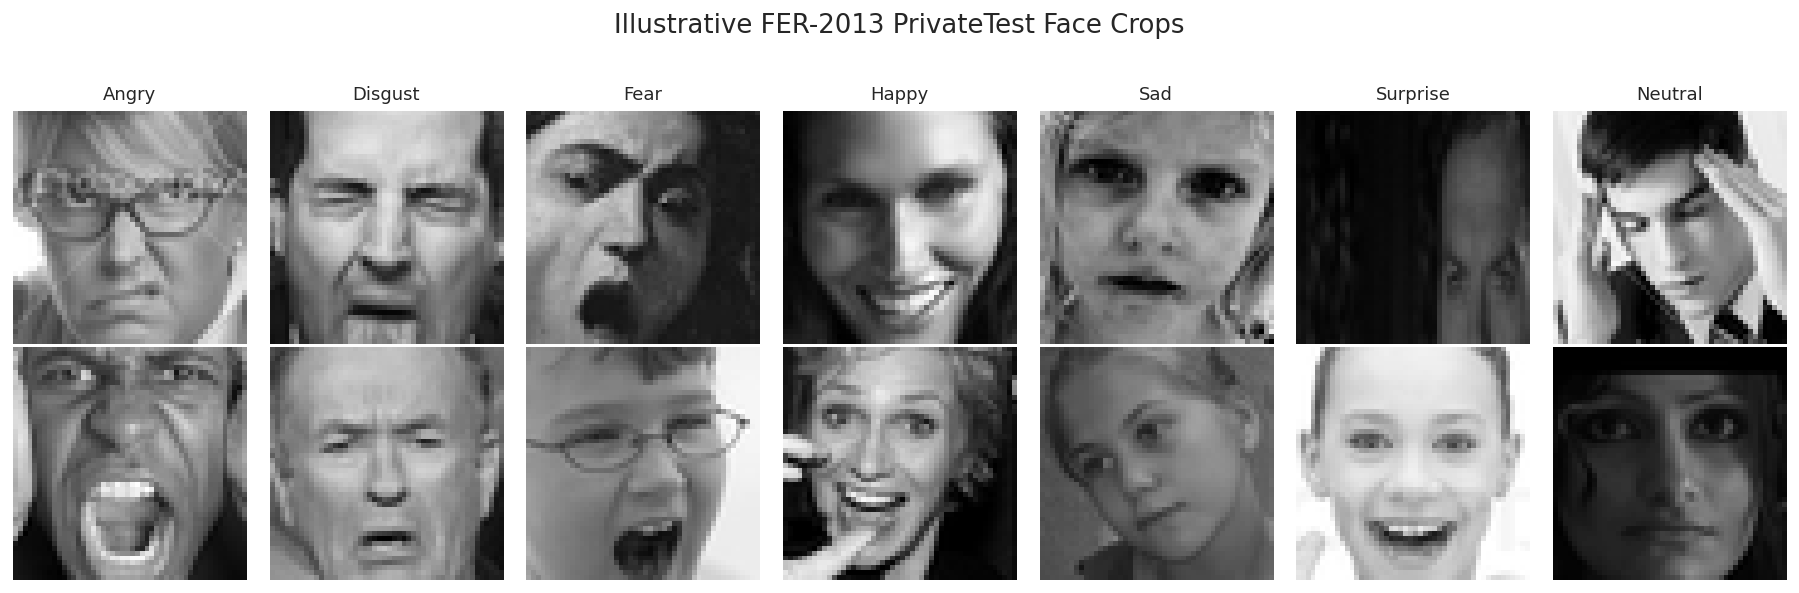

In [4]:
fig, axes = plt.subplots(2, 7, figsize=(14,4.5))
for column, label in enumerate(FACIAL_LABELS):
    subset = data[data['label'] == label].head(2)
    for row_number, pixels in enumerate(subset['pixels']):
        image = np.fromstring(pixels, sep=' ', dtype=np.uint8).reshape(48,48)
        axes[row_number, column].imshow(image, cmap='gray', vmin=0, vmax=255)
        axes[row_number, column].axis('off')
        if row_number == 0:
            axes[row_number, column].set_title(label.title(), fontsize=10)
fig.suptitle('Illustrative FER-2013 PrivateTest Face Crops', y=1.02)
plt.tight_layout()
plt.show()

### 3. Deployment preprocessing and inference

For the already cropped FER-2013 evaluation images, face localization is not
repeated. Each 48 × 48 crop is resized to 64 × 64 with bicubic interpolation,
converted to floating point, divided by 255, and scaled to `[-1, 1]`. The
deployed ONNX Runtime session then returns seven class probabilities.

In the web application, a Haar cascade first detects all frontal faces and the
largest face is selected. This evaluation therefore measures **expression
classification on provided face crops**, not real-world face-detection recall.

In [5]:
started = time.perf_counter()
y_true, y_pred, y_probability = evaluate_private_test(data, progress_every=500)
elapsed = time.perf_counter() - started
artifacts = evaluation_artifacts(y_true, y_pred, y_probability)
metrics = artifacts['metrics']
print(f'Evaluated {len(data):,} images in {elapsed:.2f} seconds')
print(f'Average crop-classification time: {elapsed / len(data) * 1000:.2f} ms/image')

Evaluated 500 / 3,589 images
Evaluated 1,000 / 3,589 images
Evaluated 1,500 / 3,589 images
Evaluated 2,000 / 3,589 images
Evaluated 2,500 / 3,589 images
Evaluated 3,000 / 3,589 images
Evaluated 3,500 / 3,589 images
Evaluated 3,589 images in 4.93 seconds
Average crop-classification time: 1.37 ms/image


### 4. Overall model performance

In [6]:
metric_table = pd.DataFrame({
    'Metric': [
        'Accuracy','Balanced accuracy','Macro F1','Weighted F1',
        'Macro ROC–AUC (OvR)','Expected calibration error (10 bins)',
        'Multiclass Brier score','Mean confidence'
    ],
    'Value': [
        metrics['accuracy'],metrics['balanced_accuracy'],metrics['macro_f1'],
        metrics['weighted_f1'],metrics['macro_roc_auc_ovr'],
        metrics['expected_calibration_error_10_bins'],
        metrics['multiclass_brier_score'],metrics['mean_confidence']
    ]
})
display(metric_table.style.format({'Value':'{:.4f}'}))

                                 Metric     Value
0                              Accuracy  0.644191
1                     Balanced accuracy  0.618269
2                              Macro F1  0.626195
3                           Weighted F1  0.642812
4                   Macro ROC–AUC (OvR)  0.908392
5  Expected calibration error (10 bins)  0.076564
6                Multiclass Brier score  0.478072
7                       Mean confidence  0.720755


**Overall interpretation.** Accuracy represents the percentage of all test
images classified correctly. Balanced accuracy gives each expression equal
importance, and macro F1 summarizes class-wise precision and recall without
allowing the larger happy or neutral classes to dominate. ROC–AUC measures
ranking quality, whereas calibration error and Brier score assess the quality
of the probability estimates.

### 5. Class-specific performance

In [7]:
report = pd.DataFrame(artifacts['classification_report']).T
class_report = report.loc[FACIAL_LABELS, ['precision','recall','f1-score','support']]
display(class_report.style.format({
    'precision':'{:.4f}','recall':'{:.4f}','f1-score':'{:.4f}','support':'{:.0f}'
}))
print(classification_report(
    y_true, y_pred, labels=np.arange(7), target_names=FACIAL_LABELS,
    digits=4, zero_division=0
))

          precision    recall  f1-score  support
angry      0.561886  0.582485  0.572000    491.0
disgust    0.738095  0.563636  0.639175     55.0
fear       0.481641  0.422348  0.450050    528.0
happy      0.862745  0.850967  0.856816    879.0
sad        0.506734  0.506734  0.506734    594.0
surprise   0.705069  0.735577  0.720000    416.0
neutral    0.613235  0.666134  0.638591    626.0
              precision    recall  f1-score   support

       angry     0.5619    0.5825    0.5720       491
     disgust     0.7381    0.5636    0.6392        55
        fear     0.4816    0.4223    0.4501       528
       happy     0.8627    0.8510    0.8568       879
         sad     0.5067    0.5067    0.5067       594
    surprise     0.7051    0.7356    0.7200       416
     neutral     0.6132    0.6661    0.6386       626

    accuracy                         0.6442      3589
   macro avg     0.6385    0.6183    0.6262      3589
weighted avg     0.6429    0.6442    0.6428      3589



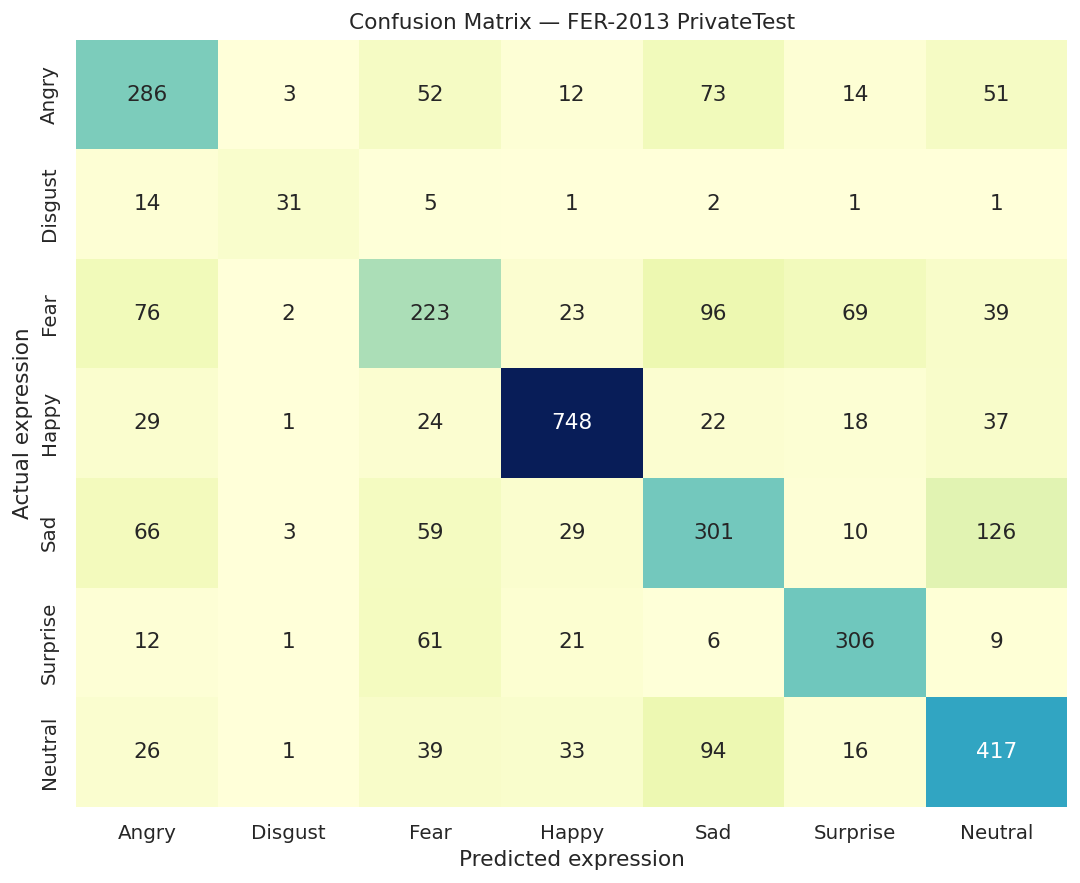

In [8]:
matrix = np.asarray(artifacts['confusion_matrix'])
fig, ax = plt.subplots(figsize=(8.5,7))
sns.heatmap(matrix, annot=True, fmt='d', cmap='YlGnBu', cbar=False,
            xticklabels=[x.title() for x in FACIAL_LABELS],
            yticklabels=[x.title() for x in FACIAL_LABELS], ax=ax)
ax.set(title='Confusion Matrix — FER-2013 PrivateTest',
       xlabel='Predicted expression', ylabel='Actual expression')
plt.tight_layout()
plt.show()

**Confusion-matrix interpretation.** Correct classifications appear on the
main diagonal. The model performs most strongly on happy expressions. Fear is
frequently confused with angry, sad, or surprise, while sad and neutral are
also commonly confused. These errors show why a single frame must not be
treated as certain knowledge of a person's emotional state.

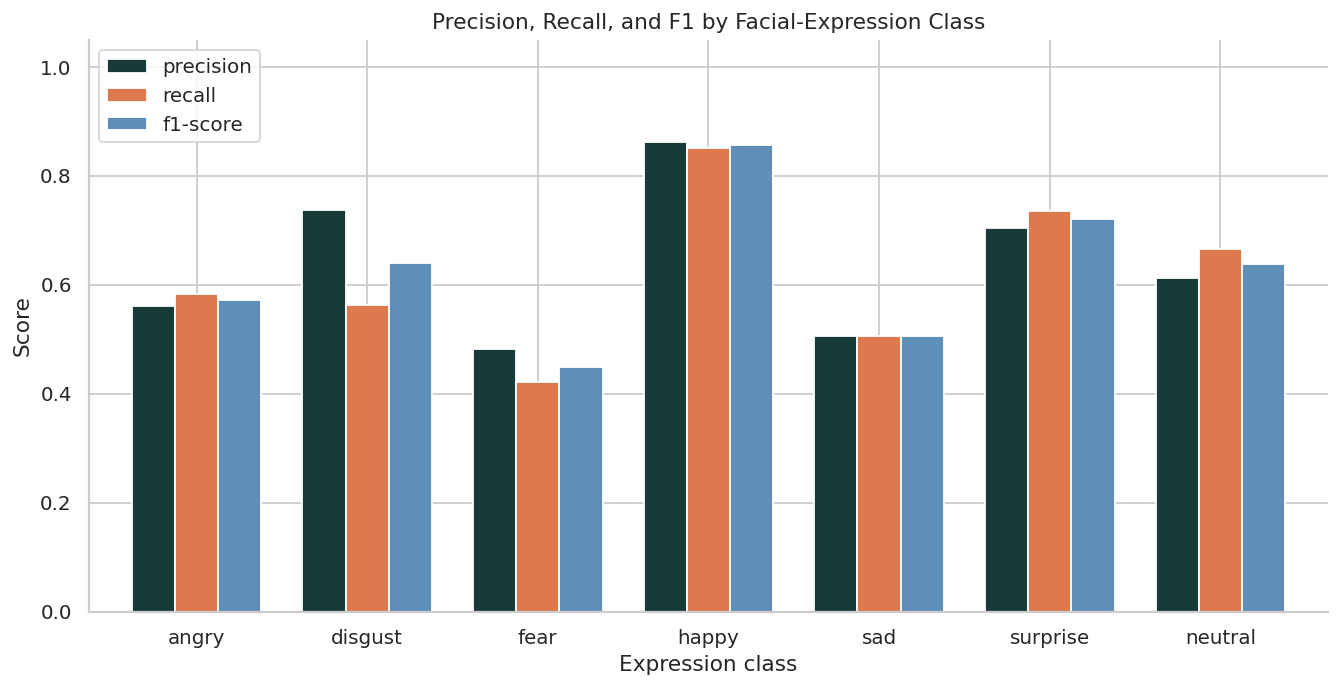

In [9]:
plot_metrics = class_report[['precision','recall','f1-score']]
ax = plot_metrics.plot(kind='bar', figsize=(10.5,5.5), width=.76,
                       color=['#173B39','#DE784D','#5F8FB8'])
ax.set(title='Precision, Recall, and F1 by Facial-Expression Class',
       xlabel='Expression class', ylabel='Score', ylim=(0,1.05))
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='upper left')
sns.despine()
plt.tight_layout()
plt.show()

### 6. One-vs-rest ROC analysis

      Class   ROC AUC
0     Angry  0.885811
1   Disgust  0.963251
2      Fear  0.816658
3     Happy  0.971557
4       Sad  0.856503
5  Surprise  0.958125
6   Neutral  0.906841


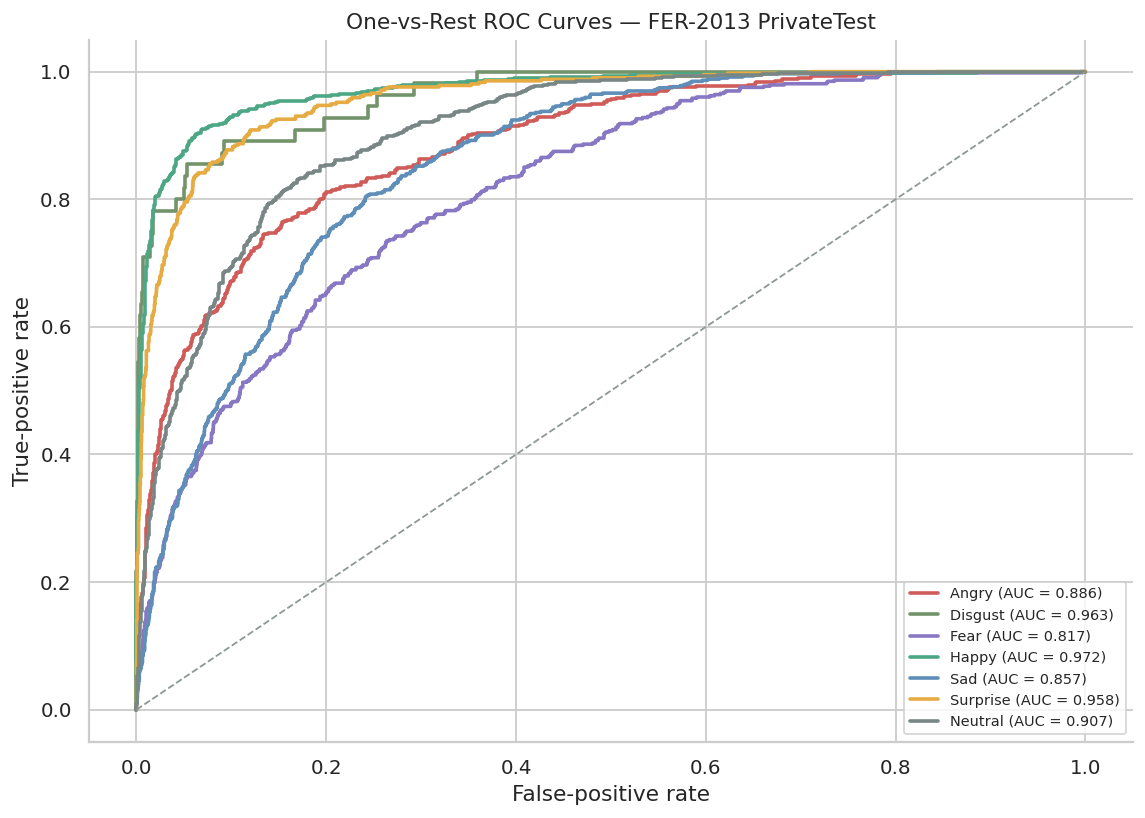

In [10]:
binary_truth = label_binarize(y_true, classes=np.arange(7))
fig, ax = plt.subplots(figsize=(9,6.5))
roc_rows = []
for index, (label, colour) in enumerate(zip(FACIAL_LABELS, palette)):
    false_positive, true_positive, _ = roc_curve(binary_truth[:,index], y_probability[:,index])
    class_auc = auc(false_positive, true_positive)
    roc_rows.append({'Class':label.title(), 'ROC AUC':class_auc})
    ax.plot(false_positive, true_positive, lw=2, color=colour,
            label=f'{label.title()} (AUC = {class_auc:.3f})')
ax.plot([0,1],[0,1],'--',color='#8d9893',lw=1)
ax.set(title='One-vs-Rest ROC Curves — FER-2013 PrivateTest',
       xlabel='False-positive rate', ylabel='True-positive rate')
ax.legend(loc='lower right', fontsize=8)
sns.despine()
plt.tight_layout()
plt.show()
display(pd.DataFrame(roc_rows).style.format({'ROC AUC':'{:.4f}'}))

### 7. Probability calibration

   Lower  Upper  Count  Mean confidence  Observed accuracy
0    0.2    0.3     33         0.273694           0.242424
1    0.3    0.4    260         0.355302           0.296154
2    0.4    0.5    495         0.452696           0.391919
3    0.5    0.6    441         0.548721           0.444444
4    0.6    0.7    401         0.648598           0.561097
5    0.7    0.8    387         0.751530           0.648579
6    0.8    0.9    465         0.849649           0.761290
7    0.9    1.0   1107         0.969550           0.909666


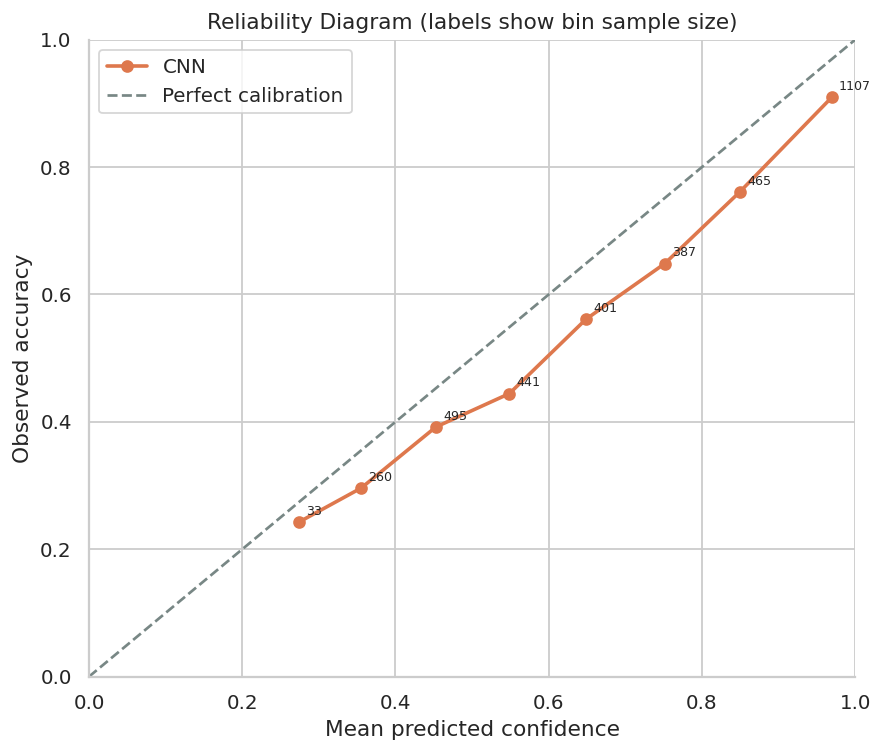

In [11]:
confidence = y_probability.max(axis=1)
correct = y_pred == y_true
edges = np.linspace(0,1,11)
calibration_rows = []
for lower, upper in zip(edges[:-1], edges[1:]):
    selected = (confidence > lower) & (confidence <= upper)
    if selected.any():
        calibration_rows.append({
            'Lower':lower, 'Upper':upper, 'Count':int(selected.sum()),
            'Mean confidence':float(confidence[selected].mean()),
            'Observed accuracy':float(correct[selected].mean())
        })
calibration = pd.DataFrame(calibration_rows)
fig, ax = plt.subplots(figsize=(7,6))
ax.plot(calibration['Mean confidence'], calibration['Observed accuracy'],
        marker='o', lw=2, color='#DE784D', label='CNN')
ax.plot([0,1],[0,1],'--',color='#788785',label='Perfect calibration')
for row in calibration.itertuples():
    ax.annotate(str(row.Count), (row._4, row._5), xytext=(4,4),
                textcoords='offset points', fontsize=7)
ax.set(title='Reliability Diagram (labels show bin sample size)',
       xlabel='Mean predicted confidence', ylabel='Observed accuracy',
       xlim=(0,1), ylim=(0,1))
ax.legend(loc='upper left')
sns.despine()
plt.tight_layout()
plt.show()
display(calibration.style.format({
    'Lower':'{:.1f}','Upper':'{:.1f}',
    'Mean confidence':'{:.4f}','Observed accuracy':'{:.4f}'
}))

**Calibration interpretation.** The expected calibration error summarizes the
gap between confidence and observed accuracy. A lower value is better. The
diagram is important because a high softmax probability is not a guarantee
that the visible-expression label is correct.

### 8. Error analysis

      Actual Predicted  Count
29       Sad   Neutral    126
15      Fear       Sad     96
40   Neutral       Sad     94
12      Fear     Angry     76
3      Angry       Sad     73
16      Fear  Surprise     69
24       Sad     Angry     66
32  Surprise      Fear     61
26       Sad      Fear     59
1      Angry      Fear     52
5      Angry   Neutral     51
17      Fear   Neutral     39


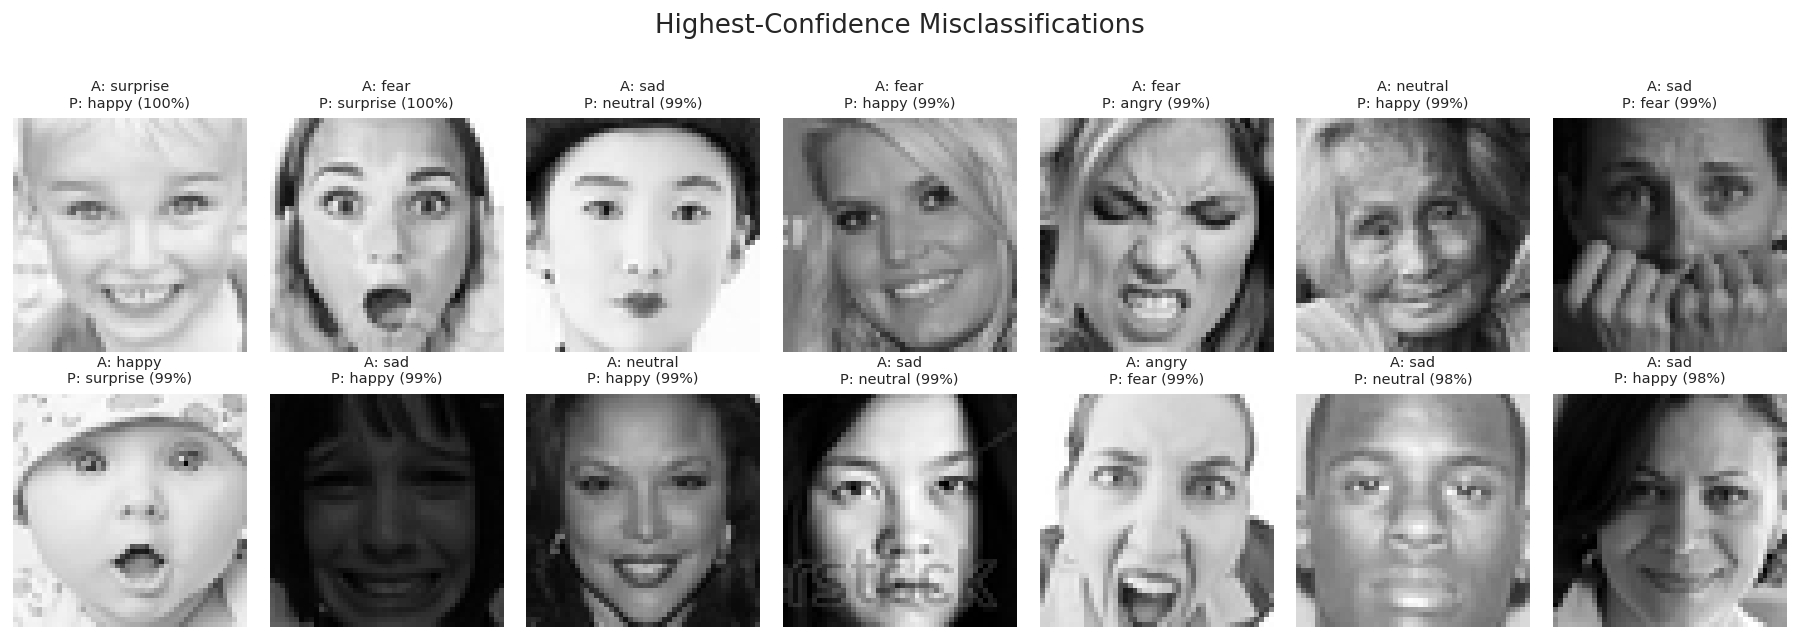

In [12]:
error_indices = np.flatnonzero(y_pred != y_true)
confusion_rows = []
for actual_index, actual_label in enumerate(FACIAL_LABELS):
    for predicted_index, predicted_label in enumerate(FACIAL_LABELS):
        if actual_index != predicted_index and matrix[actual_index,predicted_index] > 0:
            confusion_rows.append({
                'Actual':actual_label.title(), 'Predicted':predicted_label.title(),
                'Count':int(matrix[actual_index,predicted_index])
            })
confusion_pairs = pd.DataFrame(confusion_rows).sort_values('Count',ascending=False)
display(confusion_pairs.head(12))

chosen_errors = sorted(error_indices, key=lambda idx: y_probability[idx,y_pred[idx]], reverse=True)[:14]
fig, axes = plt.subplots(2,7,figsize=(14,5))
for axis, index in zip(axes.ravel(), chosen_errors):
    image = np.fromstring(data.iloc[index]['pixels'], sep=' ', dtype=np.uint8).reshape(48,48)
    axis.imshow(image,cmap='gray',vmin=0,vmax=255)
    axis.set_title(
        f"A: {FACIAL_LABELS[y_true[index]]}\nP: {FACIAL_LABELS[y_pred[index]]} ({y_probability[index,y_pred[index]]:.0%})",
        fontsize=8
    )
    axis.axis('off')
fig.suptitle('Highest-Confidence Misclassifications', y=1.01)
plt.tight_layout()
plt.show()

### 9. Save the evaluation metadata

The Flask application loads `facial_expression_model.onnx`; the metadata
below records how that exact artifact performed. The CSV images are never
saved into the web application's user database.

In [13]:
metadata = {
    'project':'MoodSense AI Local — Facial Expression Engine',
    'model_name':'FER-2013 compact CNN (ONNX)',
    'model_file':MODEL_PATH.name,
    'classes':FACIAL_LABELS,
    'evaluation_split':'FER-2013 PrivateTest',
    'evaluation_rows':len(data),
    'important_boundary':'Facial expression classification is not direct measurement of internal mood or a diagnosis.',
    **artifacts,
}
METADATA_PATH.write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Saved evaluation metadata:', METADATA_PATH)

Saved evaluation metadata: /workspace/scratch/cb04da410e0b/moodsense_local/models/facial_model_metadata.json


### 10. Example inference results

In [14]:
demo_rows = []
for class_index, label in enumerate(FACIAL_LABELS):
    index = data.index[data['emotion'] == class_index][0]
    demo_rows.append({
        'Actual expression':label.title(),
        'Predicted expression':FACIAL_LABELS[y_pred[index]].title(),
        'Confidence (%)':round(y_probability[index,y_pred[index]]*100,2)
    })
display(pd.DataFrame(demo_rows))

  Actual expression Predicted expression  Confidence (%)
0             Angry                Angry           63.39
1           Disgust              Disgust           98.16
2              Fear                Angry           71.40
3             Happy                Happy           99.93
4               Sad                  Sad           68.32
5          Surprise                Angry           35.05
6           Neutral                 Fear           60.57


## Conclusion and documentation guidance

On the 3,589-image FER-2013 PrivateTest split, the deployed ONNX CNN
achieved approximately **64.42% accuracy**, **61.83% balanced accuracy**,
**62.62% macro F1**, and **0.9084 macro one-vs-rest ROC–AUC**. Happy was the
strongest class, while fear, sad, and anger showed substantial overlap.

These results demonstrate a functional facial-expression classifier under the
FER-2013 benchmark. They do not establish a universal mood detector. FER-2013
contains low-resolution faces gathered from internet sources, facial labels can
be subjective, a single image lacks personal and cultural context, and the
notebook does not measure webcam face-detection failures. A real deployment
requires informed consent, privacy controls, representative external data,
demographic subgroup evaluation, temporal testing across video frames, and
human review.

**Suggested reporting language:** “The deployed facial-expression CNN obtained
64.42% accuracy and a macro F1-score of 62.62% on the official 3,589-image
FER-2013 PrivateTest split. The system classifies visible expression patterns
rather than directly measuring internal mood; its outputs are therefore
probabilistic cues and not psychological diagnoses.”